# Guía práctica 3

## Ejercicio 6 — TDF, SDF y TFTD

Secuencia de largo $N = 6$:

$$x[n] = [\,3,\;2,\;1,\;0,\;1,\;2\,], \qquad n = 0,\dots,5$$

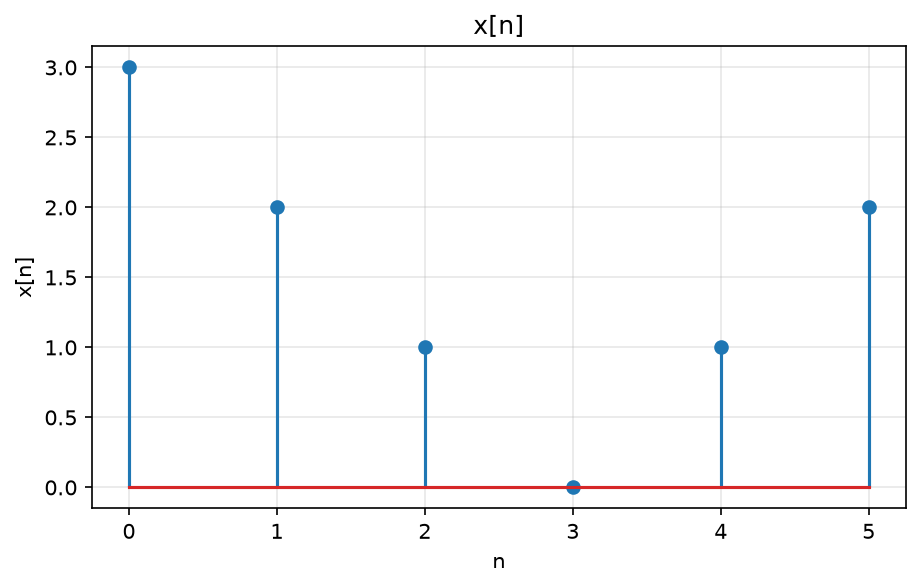

In [11]:
from matplotlib.pyplot import (
    figure,
    grid,
    legend,
    plot,
    show,
    stem,
    title,
    xlabel,
    ylabel,
)
from numpy import (
    abs,
    allclose,
    arange,
    array,
    cos,
    exp,
    linspace,
    outer,
    pi,
    real,
    sqrt,
)
from numpy.fft import fft, ifft

N = 6
n = arange(N)
x = array([3, 2, 1, 0, 1, 2])

figure(figsize=(7, 4), dpi=150)
stem(n, x)
xlabel("n")
ylabel("x[n]")
title("x[n]")
grid(True, alpha=0.3)
show()

### a) Simetría circular de $x[n]$

Evaluar $x[(-n)_6]$. Para $N = 6$ el índice $5$ hace de $-1$, el $4$ de $-2$ y el $3$ de $-3$.

In [12]:
print("x[n]      =", x)
print("x[(-n)_6] =", x[(-n) % N])
print("circularmente par :", allclose(x, x[(-n) % N]))
print("circularmente impar:", allclose(x, -x[(-n) % N]))

x[n]      = [3 2 1 0 1 2]
x[(-n)_6] = [3 2 1 0 1 2]
circularmente par : True
circularmente impar: False


$x[n]$ es circularmente par: $x[(-n)_6] = x[n]$, ya que $x[5]=x[1]=2$, $x[4]=x[2]=1$ y
$x[3]$ queda fijo en sí mismo. Por lo tanto $X^d[k]$ es **real y par**: su parte imaginaria
es cero y la fase sólo puede valer $0$ o $\pi$.

### b) Las raíces $W_6^n$ y la matriz $\mathbf{F_6}$

$$W_6 = e^{-j2\pi/6} = e^{-j\pi/3}, \qquad
\left(\mathbf{F_6}\right)_{k,n} = W_6^{kn}$$

In [13]:
W = exp(-2j * pi / N)

for i in range(N):
    print(f"W_6^{i} = {W**i:+.4f}")

F6 = W ** outer(n, n)
print("\nF6 (parte real):\n", real(F6).round(4))
print("\nF6 (parte imaginaria):\n", F6.imag.round(4))

W_6^0 = +1.0000+0.0000j
W_6^1 = +0.5000-0.8660j
W_6^2 = -0.5000-0.8660j
W_6^3 = -1.0000-0.0000j
W_6^4 = -0.5000+0.8660j
W_6^5 = +0.5000+0.8660j

F6 (parte real):
 [[ 1.   1.   1.   1.   1.   1. ]
 [ 1.   0.5 -0.5 -1.  -0.5  0.5]
 [ 1.  -0.5 -0.5  1.  -0.5 -0.5]
 [ 1.  -1.   1.  -1.   1.  -1. ]
 [ 1.  -0.5 -0.5  1.  -0.5 -0.5]
 [ 1.   0.5 -0.5 -1.  -0.5  0.5]]

F6 (parte imaginaria):
 [[ 0.     0.     0.     0.     0.     0.   ]
 [ 0.    -0.866 -0.866 -0.     0.866  0.866]
 [ 0.    -0.866  0.866  0.    -0.866  0.866]
 [ 0.    -0.     0.    -0.     0.    -0.   ]
 [ 0.     0.866 -0.866  0.     0.866 -0.866]
 [ 0.     0.866  0.866 -0.    -0.866 -0.866]]


### c) Cálculo de $X^d[k] = \mathbf{F_6}\,x$

X^d[k] = [ 9.+0.j  4.+0.j -0.-0.j  1.-0.j  0.-0.j  4.+0.j]
parte imaginaria nula: True
coincide con fft(): True

X^d[k] (real) = [ 9.  4. -0.  1.  0.  4.]


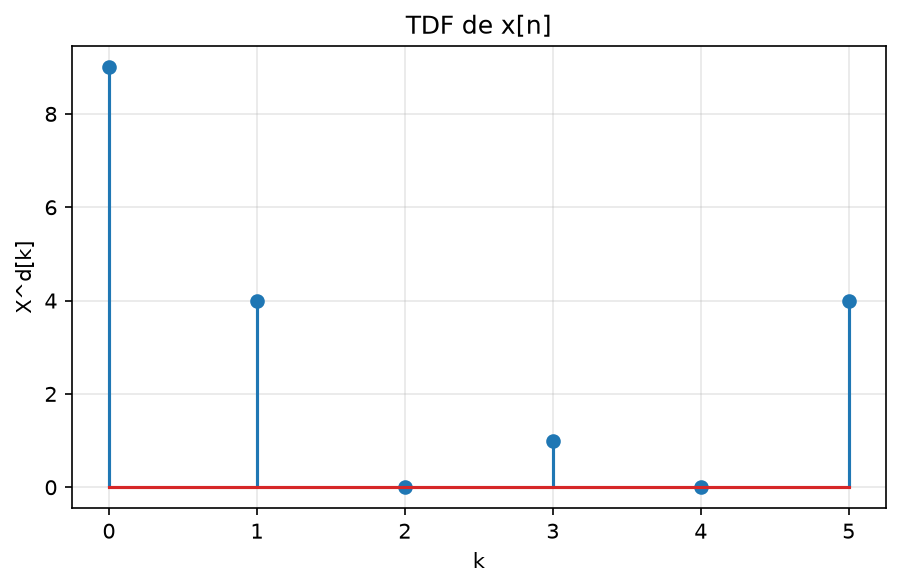

In [14]:
Xd = F6 @ x

print("X^d[k] =", Xd.round(6))
print("parte imaginaria nula:", allclose(Xd.imag, 0))
print("coincide con fft():", allclose(Xd, fft(x)))

Xd = real(Xd)
print("\nX^d[k] (real) =", Xd.round(4))

figure(figsize=(7, 4), dpi=150)
stem(n, Xd)
xlabel("k")
ylabel("X^d[k]")
title("TDF de x[n]")
grid(True, alpha=0.3)
show()

### d) Frecuencias asociadas

La TDF es el muestreo de la TFTD en $N$ puntos equiespaciados del círculo unidad:
$\theta[k] = \dfrac{2\pi k}{N}$. Con muestras cada $T = 1ms$, $f_s = 1/T = 1000Hz$.

In [15]:
T = 1e-3
fs = 1 / T

theta = 2 * pi * n / N
freqs = n * fs / N

print("theta[k] [rad] :", theta.round(4), " = k*pi/3")
print("f[k] [Hz]      :", freqs.round(2))

theta[k] [rad] : [0.     1.0472 2.0944 3.1416 4.1888 5.236 ]  = k*pi/3
f[k] [Hz]      : [  0.   166.67 333.33 500.   666.67 833.33]


La TDF toma $N$ muestras equiespaciadas de la TFTD sobre el círculo unidad, en

$$\theta[k] = \frac{2\pi k}{6} = \frac{k\pi}{3}$$

Con $T = 1\,$ms la frecuencia de muestreo es $f_s = 1/T = 1000\,$Hz, y cada índice cae en

$$f[k] = k\,\frac{f_s}{N} = 166{,}\overline{6}\,k \;\;\text{Hz}$$

o sea $0$, $166,67$, $333{,}33$, $500$, $666,67$ y $833,33Hz$.

### e) Coeficientes de la SDF de $\tilde{x}[n]$

Para la extensión periódica $\tilde{x}[n]$ de período $N$:

$$\tilde{x}[n] = \sum_{k=0}^{N-1} X^s[k]\,e^{j2\pi kn/N},
\qquad X^s[k] = \frac{1}{N}\sum_{n=0}^{N-1}\tilde{x}[n]\,e^{-j2\pi kn/N} = \frac{X^d[k]}{N}$$

In [16]:
Xs = Xd / N
print("X^s[k] = X^d[k]/6 =", Xs.round(4))

x_rec = real(sum(Xs[k] * exp(2j * pi * k * n / N) for k in range(N)))
print("\nReconstruccion sum X^s[k] exp(j2pi k n/N) =", x_rec.round(6))
print("coincide con x[n]:", allclose(x_rec, x))

X^s[k] = X^d[k]/6 = [ 1.5     0.6667 -0.      0.1667  0.      0.6667]

Reconstruccion sum X^s[k] exp(j2pi k n/N) = [ 3.  2.  1. -0.  1.  2.]
coincide con x[n]: True


### f) TFTD de un período de $\tilde{x}[n]$

Tomando el período **centrado en el origen**, $n = -3,\dots,2$:

$$x[n]\big|_{n=-3}^{2} = [\,0,\;1,\;2,\;3,\;2,\;1\,]$$

que es el triángulo $\wedge_6[n]$, no nulo para $\lvert n\rvert \le 2$ con valores
$[1,2,3,2,1]$. Dado que:

$$\wedge_6[n] = \{\sqcap_3 * \sqcap_3\}[n]$$

con $\sqcap_3[n] = 1$ para $\lvert n \rvert \le 1$. Como la convolución en el tiempo es
producto en frecuencia, y la TFTD del pulso simétrico de largo 3 es:

$$\sqcap_3[n] \;\longleftrightarrow\; X^f_{\sqcap}(\theta) = \sum_{n=-1}^{1} e^{-j\theta n} = 1 + 2\cos\theta$$

resulta:

$$\boxed{\;X^f(\theta) = \left(1 + 2\cos\theta\right)^2\;}$$

y la TDF son sus muestras: $X^d[k] = X^f\!\left(\tfrac{2\pi k}{6}\right)$.

In [17]:
print("conv([1,1,1], [1,1,1]) =", __import__("numpy").convolve([1, 1, 1], [1, 1, 1]))


def Xf(theta):
    return (1 + 2 * cos(theta)) ** 2


print("\nX^f(theta_k) =", Xf(theta).round(4))
print("X^d[k]       =", Xd.round(4))
print("coinciden    :", allclose(Xf(theta), Xd))

conv([1,1,1], [1,1,1]) = [1 2 3 2 1]

X^f(theta_k) = [9. 4. 0. 1. 0. 4.]
X^d[k]       = [ 9.  4. -0.  1.  0.  4.]
coinciden    : True


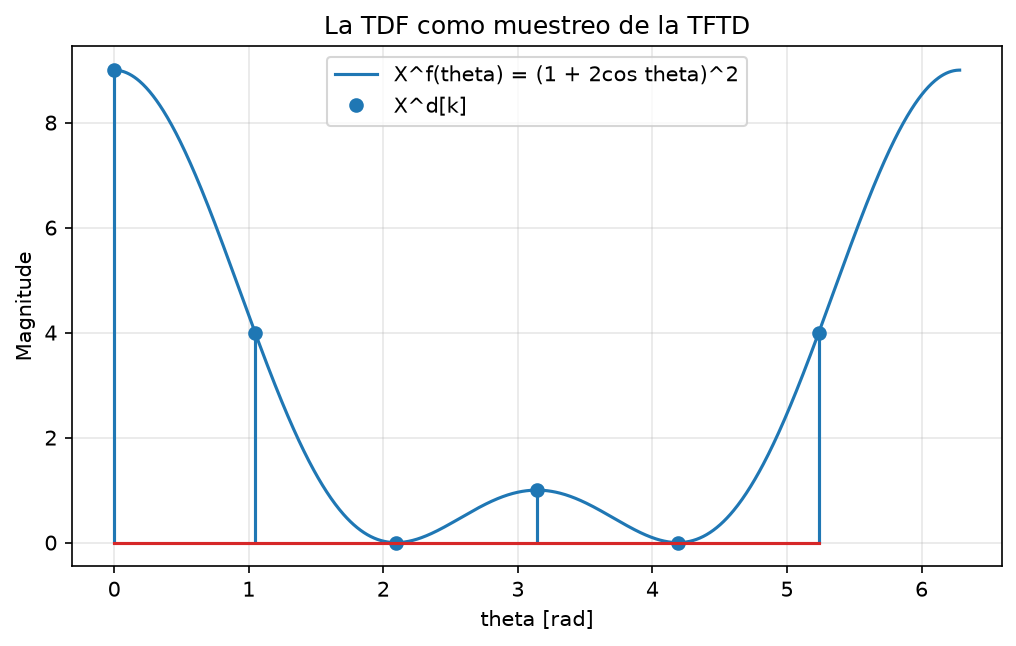

In [ ]:
th = linspace(0, 2 * pi, 1000)

figure(figsize=(8, 4.5), dpi=150)
plot(th, Xf(th), linewidth=1.5, label="X^f(theta) = (1 + 2cos theta)^2")
markers, _, _ = stem(theta, Xd)
markers.set_label("X^d[k]")
xlabel("theta [rad]")
ylabel("Magnitude")
title("La TDF como muestreo de la TFTD")
legend()
grid(True, alpha=0.3)
show()

### g) ¿Puede $x[n]$ ser una autocorrelación circular?

La autocorrelación circular de $y[n]$ cumple

$$r_{yy}[n] \;\longleftrightarrow\; \lvert Y^d[k]\rvert^2$$

Es decir, una secuencia es autocorrelación **si y sólo si** su TDF es real y **no
negativa**. Si se cumple, basta tomar $\lvert Y^d[k]\rvert = \sqrt{X^d[k]}$ y elegir
cualquier fase que devuelva una $y[n]$ real.

In [21]:
print("X^d[k]      =", Xd.round(4))
print("todos >= 0? :", (Xd >= -1e-12).all())
print("sqrt(X^d)   =", sqrt(abs(Xd)).round(4))


def circular_autocorr(y):
    return real(ifft(abs(fft(y)) ** 2))


candidates = {
    "rectangulo  [1,1,1,0,0,0]": array([1, 1, 1, 0, 0, 0]),
    "corrido     [0,0,1,1,1,0]": array([0, 0, 1, 1, 1, 0]),
}

for name, y in candidates.items():
    r = circular_autocorr(y)
    print(f"\n{name}")
    print(f"  y[n]        = {y.round(4)}")
    print(f"  autocorr    = {r.round(4)}   == x[n]? {allclose(r, x)}")

X^d[k]      = [ 9.  4. -0.  1.  0.  4.]
todos >= 0? : True
sqrt(X^d)   = [3. 2. 0. 1. 0. 2.]

rectangulo  [1,1,1,0,0,0]
  y[n]        = [1 1 1 0 0 0]
  autocorr    = [3. 2. 1. 0. 1. 2.]   == x[n]? True

corrido     [0,0,1,1,1,0]
  y[n]        = [0 0 1 1 1 0]
  autocorr    = [3. 2. 1. 0. 1. 2.]   == x[n]? True


Otras soluciones son cualquier desplazamiento circular ya que el corrimiento sólo agrega fase lineal, que el módulo al cuadrado borra.